# Initialize

In [ ]:

!pip install clean-text

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import random
import torch
import torch.nn as nn
import os

from google.colab import drive
from PIL import Image
from IPython.display import display
from cleantext import clean
from transformers import CLIPTokenizer
from transformers import CLIPImageProcessor
from transformers import CLIPModel
from torch.utils.data import Dataset, DataLoader

# Mount to the standard location without spaces
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Input Retrieval

Anwar slams critics over 2008 petrol pledge

KUALA KANGSAR: Prime Minister Datuk Seri Anwar Ibrahim has criticised those who mocked his 2008 pledge to lower petrol prices.

Anwar said his remarks from that period have been taken out of context to stir up sentiments and mislead the public.

"The statement was made when the price of oil in Saudi Arabia was 50 sen at that time," he said during a question-and-answer session at Malay College Kuala Kangsar here on Saturday (April 4).

"But we are now at RM1.99, among the lowest in the world, compared only to Brunei, which is slightly lower than us.

"All oil-producing countries, including the UAE, are now raising oil prices," he said.

Anwar had pledged in 2008 to reduce petrol prices if the Opposition at the time won the general election.

Separately, Anwar said reforms require time and cannot be achieved immediately.


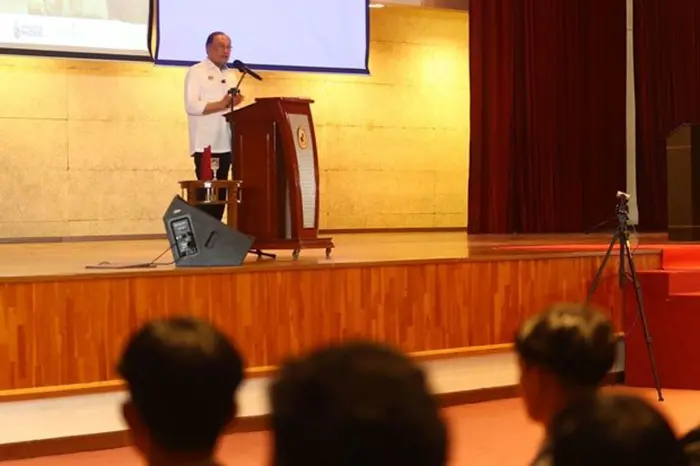

In [ ]:
# Read News Text
fake_news_text = open("/content/drive/MyDrive/Sem 6 Database/FYP/fakeNews.txt")
raw_text = fake_news_text.read()
print(raw_text)

# Read News Image
raw_image = Image.open("/content/drive/MyDrive/Sem 6 Database/FYP/fakeNews.webp").convert("RGB")
display(raw_image)

# Input Pre-processing

### Text Pre-processor

In [ ]:
# ==========================================
# PIPELINE REASONING MODULES (LLM)
# Clean the text using CleanText
# ==========================================
cleaned_text_llm = clean(raw_text,
    fix_unicode=True,
    to_ascii=True,
    lower=False,
    no_line_breaks=False,
    no_urls=True,
    no_emails=True,
    no_phone_numbers=True,
    no_numbers=False,
    no_digits=False,
    no_currency_symbols=False,
    no_punct=False,
    replace_with_url="<URL>",
    replace_with_email="<EMAIL>",
    replace_with_phone_number="<PHONE>"
)
print("\nCleaned Full Text (For LLMs):\n", cleaned_text_llm)

# ==========================================
# PIPELINE: EARLY PREDICTOR (CLIP)
# Extract the Headline and first few sentences as lead text
# ==========================================
lines = [line.strip() for line in raw_text.split('\n') if line.strip()]
lead_text = " ".join(lines[:2])
print("\nExtracted Lead Text:", lead_text)
cleaned_lead_text = clean(lead_text,
    fix_unicode=True,
    to_ascii=True,
    lower=True,
    no_line_breaks=True,
    no_urls=True,
    no_emails=True,
    no_phone_numbers=True,
    no_numbers=False,
    no_digits=False,
    no_currency_symbols=False,
    no_punct=False
)
print("Cleaned Lead Text (For CLIP):", cleaned_lead_text)



Cleaned Full Text (For LLMs):
 Anwar slams critics over 2008 petrol pledge
KUALA KANGSAR: Prime Minister Datuk Seri Anwar Ibrahim has criticised those who mocked his 2008 pledge to lower petrol prices.
Anwar said his remarks from that period have been taken out of context to stir up sentiments and mislead the public.
"The statement was made when the price of oil in Saudi Arabia was 50 sen at that time," he said during a question-and-answer session at Malay College Kuala Kangsar here on Saturday (April 4).
"But we are now at RM1.99, among the lowest in the world, compared only to Brunei, which is slightly lower than us.
"All oil-producing countries, including the UAE, are now raising oil prices," he said.
Anwar had pledged in 2008 to reduce petrol prices if the Opposition at the time won the general election.
Separately, Anwar said reforms require time and cannot be achieved immediately.

Extracted Lead Text: Anwar slams critics over 2008 petrol pledge KUALA KANGSAR: Prime Minister Dat

### Tokenizer

In [ ]:
# Tokenize text using CLIPTokenizer
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32")
tokenized_output = tokenizer(
    cleaned_lead_text,
    padding="max_length",
    truncation=True,
    max_length=77,
    return_tensors="pt"
)
input_ids = tokenized_output["input_ids"]
attention_mask = tokenized_output["attention_mask"]
print("Input IDs shape:", input_ids.shape)
print("Attention Mask shape:", attention_mask.shape)

# Pre-Processor for Image
processor = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")
processed_output = processor(images=raw_image, return_tensors="pt")
pixel_values = processed_output["pixel_values"]
print("Pixel Values shape:", pixel_values.shape)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Input IDs shape: torch.Size([1, 77])
Attention Mask shape: torch.Size([1, 77])


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Pixel Values shape: torch.Size([1, 3, 224, 224])


# Early Predictor

### CLIP

In [ ]:
# Initialize the Pre-Trained Model
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")

# Optional: Move model and tensors to GPU if available for latency optimization
# device = "cuda" if torch.cuda.is_available() else "cpu"
# model.to(device)
# input_ids = input_ids.to(device)
# attention_mask = attention_mask.to(device)
# pixel_values = pixel_values.to(device)

# During training (with LoRA), remove torch.no_grad().
with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        pixel_values=pixel_values
    )

# Extract the Projected Embeddings
text_embeds = outputs.text_embeds
image_embeds = outputs.image_embeds

print("Text Embeddings Shape:", text_embeds.shape)
print("Image Embeddings Shape:", image_embeds.shape)

# Feature Fusion (Concatenation)
combined_features = torch.cat((text_embeds, image_embeds), dim=1)
print("Combined Features Shape:", combined_features.shape)

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Text Embeddings Shape: torch.Size([1, 512])
Image Embeddings Shape: torch.Size([1, 512])
Combined Features Shape: torch.Size([1, 1024])


### Training Process


### Training CLIP

In [ ]:
# 1. Define the input path
input_file = "/content/drive/MyDrive/Sem 6 Database/FYP/fakenewsnet/PolitiFact_fake_news_content.csv"

# Load the raw dataset
df = pd.read_csv(input_file)
print(f"Original Dataset Size: {len(df)} rows")

# 2. Slice the DataFrame to keep only the required columns
df_cleaned = df[['title', 'text', 'top_img']].copy()

# 3. Apply the Label
df_cleaned['label'] = 1.0

# 4. Filter out missing images
df_cleaned = df_cleaned.dropna(subset=['top_img', 'title', 'text'])
df_cleaned = df_cleaned[df_cleaned['top_img'].str.strip() != '']
df_cleaned = df_cleaned[df_cleaned['top_img'].str.startswith('http', na=False)]

# 5. Save the Output
output_file = "/content/drive/MyDrive/Sem 6 Database/FYP/fakenewsnet/cleaned/PolitiFact_fake_cleaned.csv"
df_cleaned.to_csv(output_file, index=False)

print(f"Cleaned Dataset Size: {len(df_cleaned)} rows")
print(f"Optimized CSV saved to: {output_file}")


Original Dataset Size: 120 rows
Cleaned Dataset Size: 118 rows
Optimized CSV saved to: /content/drive/MyDrive/Sem 6 Database/FYP/fakenewsnet/cleaned/PolitiFact_fake_cleaned.csv


### Single-Layer MLP

In [ ]:
# Define the Single-Layer MLP Architecture
class EarlyPredictorMLP(nn.Module):
    def __init__(self, input_dim=1024):
        super(EarlyPredictorMLP, self).__init__()
        self.linear = nn.Linear(input_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        raw_output = self.linear(x)
        probability_score = self.sigmoid(raw_output)
        return probability_score

# Initialize the MLP
mlp_gate = EarlyPredictorMLP(input_dim=1024)

binary_prediction = mlp_gate(combined_features)

print("Early Predictor Output:", binary_prediction.item())

Early Predictor Output: 0.5008781552314758


# Knowledge Retrieval

# Multi-Agent Debate

# Judge